# Snowballing nested sampling

This notebook demonstrates the `SnowballingNestedSampler`
(`ultranest.snowballingns`), a nested sampler that advances *batches* of
`P` threads (lineages) at once, and integrates the dead points itself.

It works in *snowball rotations*: each rotation advances the `P`
lowest-likelihood thread ends in batches, buries the dead points the
front has passed (the *burial gate*), integrates them with `1/K` strips,
and then *widens* by doubling `K` with fresh prior draws for the next
rotation. The number of live points therefore grows exponentially, and
each rotation re-integrates everything at the new width.

We use the same 7-dimensional two-component sine model as in the
higher-dimensional fitting notebook, and the same data set.


## Model and data


In [1]:
import numpy as np
from numpy import sin, pi

def sine_model1(t, B, A1, P1, t1):
    return A1 * sin((t / P1 + t1) * 2 * pi) + B

def sine_model2(t, B, A1, P1, t1, A2, P2, t2):
    return A1 * sin((t / P1 + t1) * 2 * pi) + A2 * sin((t / P2 + t2) * 2 * pi) + B

np.random.seed(42)

n_data = 50
t = np.random.uniform(0, 5, size=n_data)
yerr = 1.0
y = np.random.normal(sine_model2(t, B=1.0, A1=4.2, P1=3, t1=0, A2=1.2, P2=1.2, t2=1.2), yerr)

parameters2 = ['B', 'A1', 'P1', 't1', 'A2', 'P2', 't2']


## Visualise the data


<ErrorbarContainer object of 3 artists>

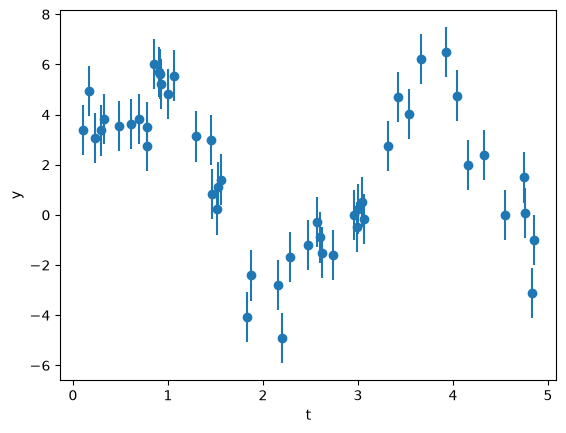

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.figure()
plt.xlabel('t')
plt.ylabel('y')
plt.errorbar(x=t, y=y, yerr=yerr, ls='none', marker='o')


## Setting up the sampler

The `SnowballingNestedSampler` takes a vectorized prior transform and a
vectorized likelihood function (arrays of points in, array of
likelihoods out), and a `log_dir` where the growing HDF5 point store,
the rotation records and the plots are written.

Its main settings:

* the number of live points starts at `num_live_points_base` (default 50)
  and doubles with each rotation (widening);
* `P` (default: half the live points, capped at 100) threads are advanced
  per batch advance;
* the direction proposal is a step sampler function, by default the
  quadratic slice direction;
* the region proposal pool (the points the directions are drawn from) is
  padded with the most recent dead points to at least `min_point_pool`
  (default 400), so small `K` still keeps proposal diversity;
* the `integrator='custom'` path integrates the dead points with `1/K`
  strips inside the state machine.


In [3]:
def prior_transform(cube):
    params = cube.copy()
    # let background level go from -10 to +10
    params[:, 0] = cube[:, 0] * 20 - 10
    # let amplitude go from 0.1 to 100
    params[:, 1] = 10**(cube[:, 1] * 3 - 1)
    # let period go from 0.3 to 30
    params[:, 2] = 10**(cube[:, 2] * 2)
    # let time go from 0 to 1
    params[:, 3] = cube[:, 3]
    params[:, 4] = 10**(cube[:, 4] * 3 - 1)
    params[:, 5] = 10**(cube[:, 5] * 2)
    params[:, 6] = cube[:, 6]
    return params

def log_likelihood(params):
    B, A1, P1, t1, A2, P2, t2 = params.transpose()
    # evaluate the model for all points at once:
    # y_model has shape (n_data, n_points)
    y_model = sine_model2(
        t[:, None], B=B[None, :], A1=A1[None, :], P1=P1[None, :],
        t1=t1[None, :], A2=A2[None, :], P2=P2[None, :], t2=t2[None, :])
    loglike = -0.5 * (((y_model - y[:, None]) / yerr)**2).sum(axis=0)
    # avoid unnecessary multiple solutions:
    #    force ordering by period from large to small
    swap = P1 < P2
    loglike[swap] = -1e300 * np.abs(P1[swap] - P2[swap])
    return loglike

from ultranest.snowballingns import SnowballingNestedSampler

sampler = SnowballingNestedSampler(
    parameters2, log_likelihood, transform=prior_transform,
    vectorized=True, num_steps=1, integrator='custom',
    log_dir='chains/snowball-quicklook')


## Quick-look result: a single rotation

`run(max_num_live_points=50)` stops after a single rotation (the
live points start at `num_live_points_base=50` and the limit is
reached at the first rotation boundary): the `K=50` threads are
advanced in batches of `P=25` until the `frac_remain` criterion
fires, and the buried dead points are integrated with `1/K` strips.
The corner plot is written to `log_dir`.


In [4]:
result = sampler.run(frac_remain=0.5, max_num_live_points=50,
                     resume=False)
sampler.plot_corner()

from IPython.display import IFrame
IFrame('chains/snowball-quicklook/corner.pdf', width=620, height=480)


[ultranest.SnowballingNestedSampler] Z=-1000000000000000052504760255204420248704468581108159154915854115511802457988908195786371375080447864043704443832883878176942523235360430575644792184786706982848387200926575803737830233794788090059368953234970799945081119038967640880074652742780142494579258788820056842838115669472196386865459400540160.0(0.00%) | Like=-39068810247132300386259744651790071551337800505636702267876413856549678022785258420340188523483416742341363659631524541438697003640629215222998703735713866146169361532487783564349228788485875728053451181421964694514529127611893090181099429182949330368232246767498409267733462733765850820350212590010368.00..-222.80 | it/evals=7/300 N=50


[ultranest.SnowballingNestedSampler] Z=-524284443940344737986431438575158800472634097683588848569063502801438894680380064248030553690149102083148406003628790339662978067534303427555276286129331195342907886355767527989592889836482881774199994232957879742121172924396269757352727057076543652022466873160794876452595695815156772164432992141312.0(0.00%) | Like=-490153657996605031784776084555623500963475264399698200612267807818354146213004722976886674401044442595521991116245977658478862693079729362651626552692688136181337060094411846178525145923605417913140936589016799219091850573822778976556339768331855412766619690135305190497270016265737706246136959860736.00..-222.80 | it/evals=35/700 N=50


[ultranest.SnowballingNestedSampler] Z=-42225.2(0.00%) | Like=-24697.42..-222.18 | it/evals=51/975 N=50


[ultranest.SnowballingNestedSampler] Z=-2236.0(0.00%) | Like=-2159.09..-222.18 | it/evals=85/1275 N=50


[ultranest.SnowballingNestedSampler] Z=-1771.2(0.00%) | Like=-1747.60..-219.18 | it/evals=96/1575 N=50


[ultranest.SnowballingNestedSampler] Z=-1023.6(0.00%) | Like=-970.73..-198.77 | it/evals=117/1800 N=50


... (38 outputs left out)


logZ = -55.053 +- 0.577



    B                   : 0.03  │▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▄▇▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁ ▁│0.97      0.55 +- 0.11
    A1                  : 0.00  │▁▁▁▁▂▁▁▁▁▁▃▃▁▂▁▁▁▁▁▅▇▇▁▁▁▁▁▁▁▁▁▁▁▁▁  ▁▁▁│1.00      0.42 +- 0.16
    P1                  : 0.01  │▁▁  ▁▁▁▁▂▇▁▁▁▁▁ ▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁│1.00      0.44 +- 0.24
    t1                  : 0.01  │▁ ▁▁▁    ▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▂▃▇│1.00      0.82 +- 0.20
    A2                  : 0.00  │▁▁▁▁▁▂▃▇▃▂▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁   ▁▁▁▁ ▁│0.99      0.25 +- 0.15
    P2                  : 0.00  │▁▁▁▁▁▁▁▂▃▇▇▂▁▁▁▁▁ ▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁ ▁▁▁ ▁│0.86      0.24 +- 0.13
    t2                  : 0.00  │▁▁▁▁▁▁▇▆▄▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▄▄│1.00      0.45 +- 0.35

[ultranest.SnowballingNestedSampler] Gompertz convergence: needs at least 3 rotations


[ultranest.SnowballingNestedSampler] max_num_live_points=50 reached before convergence (K=50); stopping.


[ultranest.SnowballingNestedSampler] convergence criterion fulfilled: False


### Reading the output

The printed line `rotation 1: K=50, N buried cells, lnZ = ... +- ...`
reports:

* `K` – the number of live points (threads) used in this rotation;
* `N buried cells` – how many dead points passed the burial gate; each is
  one completed walk, integrated with a `1/K` strip;
* `lnZ +- ...` – the evidence integrated so far, plus the estimated error
  `sqrt(H/K)` (the information divided by the live points).

The final line `convergence criterion fulfilled: False` reports whether
the Gompertz looping criterion fired. With a single rotation it cannot:
this is *not* a converged result.

The corner plot shows the quick-look posterior: the buried dead points,
weighted by their `1/K` strips, plus the thread ends, weighted by the
remaining volume. After one rotation the remaining-volume term still
holds a large share of the probability mass, so the evidence is only
partial and the posterior is broad — it is a look at where the sampler
is, not a final answer.


## Full run

The full run lets the rotations widen `K` until the Gompertz looping
criterion says the next doubling is not worth it. The `max_ncalls` and
`max_time` budgets terminate the run at the next rotation boundary even
if the criterion has not fired — and `results['converged']` records
whether it did. The final corner plot is written as `corner.pdf`.


In [5]:
full_sampler = SnowballingNestedSampler(
    parameters2, log_likelihood, transform=prior_transform,
    vectorized=True, num_steps=1, integrator='custom',
    log_dir='chains/snowball-full')

result = full_sampler.run(
    frac_remain=0.5, max_ncalls=1000000,
    max_execution_time_in_s=2*60*60, resume=False)


[ultranest.SnowballingNestedSampler] Z=-1000000000000000052504760255204420248704468581108159154915854115511802457988908195786371375080447864043704443832883878176942523235360430575644792184786706982848387200926575803737830233794788090059368953234970799945081119038967640880074652742780142494579258788820056842838115669472196386865459400540160.0(0.00%) | Like=-17891573283742617288328016752379031454735780687631796551711015599892259528135407947815910546327100927857147579576809053018022859097838076974851224798988903861060621480071280326639226913502685365530891312322935269628985453489066076431263320923770709356193243556619541886889780319442714577496741429379072.00..-306.88 | it/evals=8/250 N=50


[ultranest.SnowballingNestedSampler] Z=-74107.3(0.00%) | Like=-62562.96..-212.91 | it/evals=35/525 N=50


[ultranest.SnowballingNestedSampler] Z=-2725.0(0.00%) | Like=-2464.83..-208.58 | it/evals=61/900 N=50


[ultranest.SnowballingNestedSampler] Z=-2267.2(0.00%) | Like=-2249.24..-208.58 | it/evals=65/1125 N=50


[ultranest.SnowballingNestedSampler] Z=-834.9(0.00%) | Like=-803.09..-208.58 | it/evals=107/1450 N=50


[ultranest.SnowballingNestedSampler] Z=-547.7(0.00%) | Like=-539.95..-180.54 | it/evals=128/1675 N=50


... (928 outputs left out)


logZ = -54.126 +- 0.071

    B                   : 0.000 │▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▇▇▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁│1.000     0.561 +- 0.091
    A1                  : 0.00  │▁▁▁▁▁▁▁▁▁▁▁▂▂▁▁▁▁▁▁▁▁▇▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁│1.00      0.39 +- 0.17
    P1                  : 0.00  │▁▁▁▁▁▁▁▁▁▇▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁│1.00      0.50 +- 0.26
    t1                  : 0.00  │▇▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁│1.00      0.31 +- 0.30
    A2                  : 0.00  │▁▁▁▁▁▁▁▄▄▂▂▁▁▁▁▁▁▁▁▂▄▇▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁│1.00      0.36 +- 0.17
    P2                  : 0.00  │▆▂▁▁▁▁▁▁▂▇▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁│1.00      0.19 +- 0.16
    t2                  : 0.00  │▄▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▃▇│1.00      0.63 +- 0.39



[ultranest.SnowballingNestedSampler] Gompertz convergence: 20/20 segments predicted to improve in the next rotation


[ultranest.SnowballingNestedSampler] max_ncalls=1000000 reached before convergence (ncall=1659525); stopping.


[ultranest.SnowballingNestedSampler] convergence criterion fulfilled: False


In [6]:
full_sampler.plot_corner()
full_sampler.plot_sequences()
full_sampler.plot_rotations()

from IPython.display import IFrame
IFrame('chains/snowball-full/corner.pdf', width=620, height=480)
print('lnZ = %.3f +- %.3f' % (result['logz'], result['logzerr']))
print('converged:', result['converged'])


lnZ = -54.126 +- 0.071
converged: False


The corner plot now shows the posterior from the accumulated dead
points of all rotations, weighted by their strips, with the thread ends
contributing only a small remaining-volume weight. The `K` of the last
rotation is the accuracy knob: the error estimate scales as
`sqrt(H/K)`.